Ghi chú ngày 5: Logistic regression và Softmax regression
## Logistic Regression


In [1]:
# 0 — Import thư viện
import warnings
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression          # chỉ để đối chiếu

np.set_printoptions(precision=6, suppress=True)

In [2]:
# 0.1 — Dùng lại từ ngày 3: add_bias, MyStandardScaler
def add_bias(X):
    """Thêm cột 1 vào đầu: (n, d) -> (n, d+1)."""
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    return np.hstack([np.ones((X.shape[0], 1)), X])

class MyStandardScaler:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)          # ddof=0 giống sklearn
        self.scale_[self.scale_ == 0] = 1.0  # tránh chia 0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [3]:
# 0.2 — Dùng lại từ ngày 4: numerical_grad, rel_error, train_gd
#   Sửa nhỏ so với ngày 4:
#   - numerical_grad duyệt w.flat để dùng được cho cả ma trận W (softmax).
#   - train_gd nhận loss_fn, grad_fn, w0 thay vì gắn cứng vào MSE;
#     seed có thể là một Generator để train tiếp (warm start) không lặp lại thứ tự xáo trộn.
def numerical_grad(f, w, eps=1e-5):
    w = np.asarray(w, dtype=float)
    g = np.zeros_like(w)
    for i in range(w.size):
        e = np.zeros_like(w)
        e.flat[i] = eps
        g.flat[i] = (f(w + e) - f(w - e)) / (2 * eps)
    return g

def rel_error(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))

def train_gd(X, y, loss_fn, grad_fn, w0, lr=0.01, batch_size=None, epochs=50, momentum=0.0, seed=0):
    """batch_size=None: batch GD; 1: SGD; số khác: mini-batch.
    Trả về w và danh sách loss trên toàn tập train sau mỗi epoch."""
    rng = np.random.default_rng(seed)
    n = X.shape[0]
    B = n if batch_size is None else batch_size
    w = np.array(w0, dtype=float)
    v = np.zeros_like(w)                 # vận tốc cho momentum
    losses = []
    for _ in range(epochs):
        perm = rng.permutation(n)        # xáo trộn mỗi epoch
        for start in range(0, n, B):
            b = perm[start:start + B]
            v = momentum * v - lr * grad_fn(w, X[b], y[b])
            w = w + v
        losses.append(loss_fn(w, X, y))
        if not np.isfinite(losses[-1]):  # phân kỳ: dừng sớm
            break
    return w, losses

## Bài 1 — Các hàm nền tảng

In [4]:
# 1.1 — sigmoid ổn định số
#   z ≥ 0: 1 / (1 + e^{-z})      (e^{-z} ≤ 1, không tràn)
#   z < 0: e^{z} / (1 + e^{z})   (e^{z} < 1, không tràn)
#   Cả hai nhánh chỉ cần e^{-|z|}, nên tính exp một lần trên -|z|.
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

z = np.array([-1000, 0, 1000])
with warnings.catch_warnings():
    warnings.simplefilter("error")          # biến mọi cảnh báo thành lỗi
    print("sigmoid ổn định :", sigmoid(z))

with np.errstate(over="warn"), warnings.catch_warnings(record=True) as w_naive:
    warnings.simplefilter("always")
    naive = 1 / (1 + np.exp(-z))
print("sigmoid ngây thơ:", naive, "| cảnh báo:", [str(w.message) for w in w_naive])

sigmoid ổn định : [0.  0.5 1. ]
sigmoid ngây thơ: [0.  0.5 1. ] | cảnh báo: ['overflow encountered in exp']


In [5]:
# 1.2 — BCE từ logit bằng np.logaddexp
#   ℓ(z, y) = −[y·log σ(z) + (1−y)·log(1−σ(z))]
#   log σ(z) = −log(1 + e^{−z}),  log(1−σ(z)) = −z − log(1 + e^{−z})
#   ⇒ ℓ(z, y) = log(1 + e^{z}) − y·z = logaddexp(0, z) − y·z
def bce_from_logits(z, y):
    return np.mean(np.logaddexp(0, z) - y * z)

def bce_from_probs(p, y, eps=1e-15):
    p = np.clip(p, eps, 1 - eps)                 # kẹp để tránh log(0)
    return np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p)))

cases = [(0.0, 1), (2.0, 1), (-2.0, 1), (20.0, 0), (40.0, 0), (1000.0, 0), (-1000.0, 1)]
print(f"{'z':>8s}{'y':>3s}{'từ logit':>14s}{'qua xác suất kẹp':>18s}")
for zi, yi in cases:
    a = bce_from_logits(np.array([zi]), np.array([yi]))
    b = bce_from_probs(sigmoid(np.array([zi])), np.array([yi]))
    print(f"{zi:8.0f}{yi:3d}{a:14.6f}{b:18.6f}")

       z  y      từ logit  qua xác suất kẹp
       0  1      0.693147          0.693147
       2  1      0.126928          0.126928
      -2  1      2.126928          2.126928
      20  0     20.000000         20.000000
      40  0     40.000000         34.539576
    1000  0   1000.000000         34.539576
   -1000  1   1000.000000         34.538776


**Nhận xét 1.2:** Với logit vừa phải, hai cách cho kết quả giống nhau. Khi dự đoán sai và rất tự tin (z = 40 hoặc 1000 mà y = 0), σ(z) làm tròn thành đúng 1.0 trong float64. Lúc đó cách qua xác suất bị kẹp ở −log(1e-15) ≈ 34.54, không phân biệt được z = 40 với z = 1000, và gradient của loss theo z cũng mất. Cách tính từ logit cho đúng giá trị ≈ z (40, 1000), không bị kẹp và không cần ε.

In [6]:
# 1.3 — softmax ổn định số cho ma trận (n, K): trừ max mỗi hàng trước khi exp
def softmax(Z):
    Z = np.asarray(Z, dtype=float)
    Z = Z - Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

Z_test = np.array([[1.0, 2.0, 3.0],
                   [1000.0, 1001.0, 1002.0],
                   [-1000.0, 0.0, 1000.0],
                   [5.0, 5.0, 5.0]])
P_test = softmax(Z_test)
print(P_test)
print("tổng mỗi hàng:", P_test.sum(axis=1))
assert np.allclose(P_test.sum(axis=1), 1) and np.all(np.isfinite(P_test))
print("hàng 0 và hàng 1 giống nhau (softmax bất biến khi cộng hằng):", np.allclose(P_test[0], P_test[1]))

[[0.090031 0.244728 0.665241]
 [0.090031 0.244728 0.665241]
 [0.       0.       1.      ]
 [0.333333 0.333333 0.333333]]
tổng mỗi hàng: [1. 1. 1. 1.]
hàng 0 và hàng 1 giống nhau (softmax bất biến khi cộng hằng): True


## Bài 2 — Logistic regression trên dữ liệu 2D

In [7]:
# 2.1 — Sinh dữ liệu
X2, y2 = make_classification(n_samples=400, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=1)
print(X2.shape, np.bincount(y2))

(400, 2) [201 199]


In [8]:
# 2.2 — class LogisticRegressionGD
class LogisticRegressionGD:
    def __init__(self, lr=0.1, batch_size=None, epochs=100, momentum=0.0, seed=0):
        self.lr, self.batch_size, self.epochs = lr, batch_size, epochs
        self.momentum, self.seed = momentum, seed

    # loss và gradient theo w (X đã có cột bias)
    @staticmethod
    def loss(w, X, y):
        return bce_from_logits(X @ w, y)

    @staticmethod
    def grad(w, X, y):
        return X.T @ (sigmoid(X @ w) - y) / len(y)

    def fit(self, X, y):
        Xb = add_bias(X)
        w, self.loss_history_ = train_gd(
            Xb, y, self.loss, self.grad, np.zeros(Xb.shape[1]),
            lr=self.lr, batch_size=self.batch_size, epochs=self.epochs,
            momentum=self.momentum, seed=self.seed)
        self.intercept_, self.coef_ = w[0], w[1:]
        return self

    def decision_function(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

    def predict_proba(self, X):
        """Xác suất lớp 1, shape (n,)."""
        return sigmoid(self.decision_function(X))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [9]:
# 2.3 — Kiểm tra gradient trước khi train
rng = np.random.default_rng(0)
X2b = add_bias(X2)
w_rand = rng.normal(size=X2b.shape[1])

g_ana = LogisticRegressionGD.grad(w_rand, X2b, y2)
g_num = numerical_grad(lambda w: LogisticRegressionGD.loss(w, X2b, y2), w_rand)
err = rel_error(g_ana, g_num)
print("giải tích:", g_ana)
print("số       :", g_num)
print(f"sai khác tương đối = {err:.2e}")
assert err < 1e-7, "Gradient sai!"

giải tích: [0.170788 0.436256 0.287392]
số       : [0.170788 0.436256 0.287392]
sai khác tương đối = 6.48e-12


w = -0.23850194904855213 [-3.537209 -0.58852 ]
loss cuối = 0.1330,  accuracy train = 0.9625


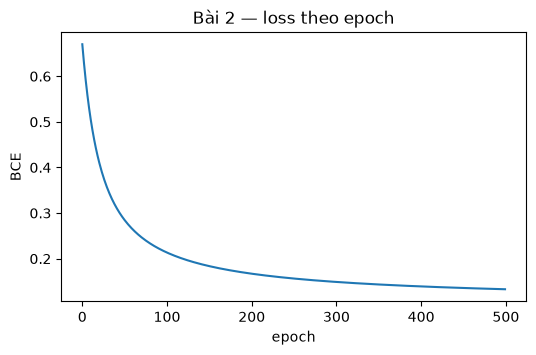

In [10]:
# 2.3b — Train (batch GD) + loss theo epoch
clf2 = LogisticRegressionGD(lr=0.1, epochs=500).fit(X2, y2)
print("w =", clf2.intercept_, clf2.coef_)
print(f"loss cuối = {clf2.loss_history_[-1]:.4f},  accuracy train = {np.mean(clf2.predict(X2) == y2):.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(clf2.loss_history_)
plt.xlabel("epoch"); plt.ylabel("BCE"); plt.title("Bài 2 — loss theo epoch"); plt.show()

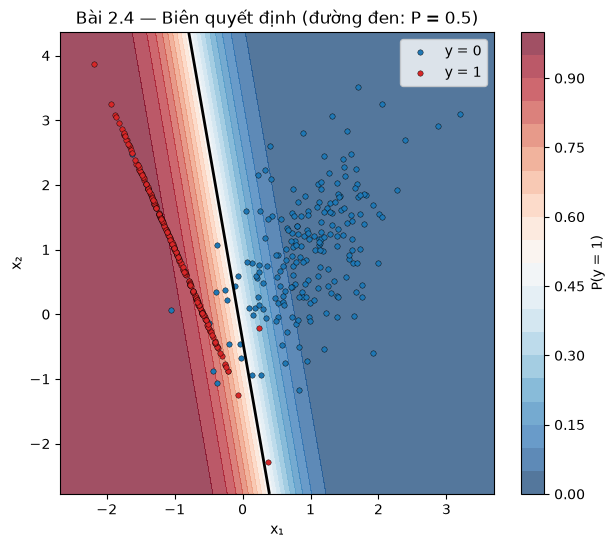

In [11]:
# 2.4 — Dữ liệu + biên quyết định
pad = 0.5
xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - pad, X2[:, 0].max() + pad, 300),
                     np.linspace(X2[:, 1].min() - pad, X2[:, 1].max() + pad, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
proba = clf2.predict_proba(grid).reshape(xx.shape)

plt.figure(figsize=(7, 6))
cf = plt.contourf(xx, yy, proba, levels=20, cmap="RdBu_r", alpha=0.7)
plt.colorbar(cf, label="P(y = 1)")
plt.contour(xx, yy, proba, levels=[0.5], colors="k", linewidths=2)
plt.scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], s=15, c="tab:blue", edgecolor="k", lw=0.3, label="y = 0")
plt.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], s=15, c="tab:red", edgecolor="k", lw=0.3, label="y = 1")
plt.xlabel("x₁"); plt.ylabel("x₂"); plt.legend()
plt.title("Bài 2.4 — Biên quyết định (đường đen: P = 0.5)"); plt.show()

**Nhận xét 2.4:** Biên quyết định là đường thẳng w₀ + w₁x₁ + w₂x₂ = 0, vì sigmoid đơn điệu nên P = 0.5 tương đương z = 0. Xác suất thay đổi mượt khi đi xa khỏi biên. Các điểm nằm sai phía là những điểm hai cụm chồng lên nhau, nên không đường thẳng nào tách hết được.

## Bài 3 — Breast Cancer

In [12]:
# 3.1 — Tải dữ liệu (0 = ác tính, 1 = lành tính)
bc = load_breast_cancer()
X_bc, y_bc = bc.data, bc.target
print(X_bc.shape, "| số mẫu mỗi lớp:", dict(zip(bc.target_names, np.bincount(y_bc))))

(569, 30) | số mẫu mỗi lớp: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


In [13]:
# 3.2 — Chia 80/20 có stratify, chuẩn hóa bằng scaler ngày 3 (chỉ fit trên train)
Xtr_bc, Xte_bc, ytr_bc, yte_bc = train_test_split(
    X_bc, y_bc, test_size=0.2, stratify=y_bc, random_state=42)
scaler_bc = MyStandardScaler().fit(Xtr_bc)
Xtr_bc_s, Xte_bc_s = scaler_bc.transform(Xtr_bc), scaler_bc.transform(Xte_bc)
print(Xtr_bc_s.shape, Xte_bc_s.shape)
print("tỉ lệ lớp 1 — train:", ytr_bc.mean().round(4), " test:", yte_bc.mean().round(4))

(455, 30) (114, 30)
tỉ lệ lớp 1 — train: 0.6264  test: 0.6316


loss train cuối = 0.0530
accuracy test   = 0.9649


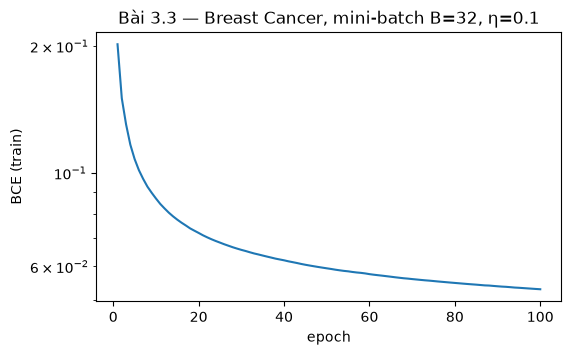

In [14]:
# 3.3 — Mini-batch GD, loss theo epoch, accuracy test
clf_bc = LogisticRegressionGD(lr=0.1, batch_size=32, epochs=100).fit(Xtr_bc_s, ytr_bc)
acc_ours = np.mean(clf_bc.predict(Xte_bc_s) == yte_bc)
print(f"loss train cuối = {clf_bc.loss_history_[-1]:.4f}")
print(f"accuracy test   = {acc_ours:.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(clf_bc.loss_history_) + 1), clf_bc.loss_history_)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("BCE (train)")
plt.title("Bài 3.3 — Breast Cancer, mini-batch B=32, η=0.1"); plt.show()

In [15]:
# 3.4 — So với sklearn LogisticRegression(penalty=None, max_iter=5000)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)   # sklearn ≥ 1.8 báo penalty sắp bỏ, khuyên dùng C=np.inf
    sk_bc = LogisticRegression(penalty=None, max_iter=5000).fit(Xtr_bc_s, ytr_bc)
acc_sk = sk_bc.score(Xte_bc_s, yte_bc)
print(f"accuracy test — ours: {acc_ours:.4f}   sklearn: {acc_sk:.4f}")

print("\nP(y=1) của 5 mẫu test đầu tiên:")
print("ours   :", clf_bc.predict_proba(Xte_bc_s[:5]).round(4))
print("sklearn:", sk_bc.predict_proba(Xte_bc_s[:5])[:, 1].round(4))
print("nhãn   :", yte_bc[:5])

print(f"\nmax |w| — ours: {np.abs(clf_bc.coef_).max():.2f}   sklearn: {np.abs(sk_bc.coef_).max():.2f}")
print(f"loss train — ours: {clf_bc.loss_history_[-1]:.4f}   "
      f"sklearn: {LogisticRegressionGD.loss(np.r_[sk_bc.intercept_, sk_bc.coef_.ravel()], add_bias(Xtr_bc_s), ytr_bc):.2e}")

accuracy test — ours: 0.9649   sklearn: 0.9211

P(y=1) của 5 mẫu test đầu tiên:
ours   : [0.     1.     0.0043 0.4518 0.    ]
sklearn: [0. 1. 0. 1. 0.]
nhãn   : [0 1 0 1 0]

max |w| — ours: 1.15   sklearn: 360.41
loss train — ours: 0.0530   sklearn: 4.69e-04


**Nhận xét 3.4:**
- Hai mô hình **không** cho cùng kết quả, và sklearn còn kém hơn trên test. Nguyên nhân là tập train gần như tách được tuyến tính. Khi không có regularization, nghiệm tối ưu của BCE nằm ở vô cùng: cứ phóng to w thì loss train càng tiến về 0. lbfgs của sklearn chạy tới 5000 vòng nên đẩy |w| lên hàng trăm, loss train gần 0, xác suất gần như toàn 0 hoặc 1, và bị **overfit**.
- GD của mình chỉ chạy 100 epoch từ w = 0 nên |w| còn nhỏ (~1). Việc dừng sớm đóng vai trò như regularization ngầm (early stopping). Xác suất mềm hơn, và mẫu khó (ví dụ mẫu thứ 4) có P gần 0.5 thay vì bị ép về 0 hoặc 1.
- Bài học: logistic regression không regularize trên dữ liệu tách được thì không có nghiệm hữu hạn. Thực tế nên dùng penalty L2 (mặc định của sklearn) hoặc early stopping.

## Bài 4 — Ngưỡng và ma trận nhầm lẫn (tự viết)

In [16]:
# 4.1 — Ác tính là lớp dương tính: y_pos = 1 − y, train lại cùng cấu hình
ytr_pos, yte_pos = 1 - ytr_bc, 1 - yte_bc
clf_pos = LogisticRegressionGD(lr=0.1, batch_size=32, epochs=100).fit(Xtr_bc_s, ytr_pos)
p_pos = clf_pos.predict_proba(Xte_bc_s)
print("số ca ác tính trong test:", yte_pos.sum(), "/", len(yte_pos))

số ca ác tính trong test: 42 / 114


In [17]:
# 4.2 — Tự đếm TP, FP, FN, TN bằng NumPy
def confusion_counts(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(bool), np.asarray(y_pred).astype(bool)
    tp = np.sum(y_pred & y_true)
    fp = np.sum(y_pred & ~y_true)
    fn = np.sum(~y_pred & y_true)
    tn = np.sum(~y_pred & ~y_true)
    return tp, fp, fn, tn

print(f"{'ngưỡng':>7s}{'TP':>5s}{'FP':>5s}{'FN':>5s}{'TN':>5s}{'recall':>9s}{'precision':>11s}{'accuracy':>10s}")
for t in [0.3, 0.5, 0.7]:
    tp, fp, fn, tn = confusion_counts(yte_pos, p_pos >= t)
    print(f"{t:7.1f}{tp:5d}{fp:5d}{fn:5d}{tn:5d}"
          f"{tp / (tp + fn):9.3f}{tp / (tp + fp):11.3f}{(tp + tn) / len(yte_pos):10.3f}")

print("\nxác suất ác tính của các ca ác tính bị bỏ sót ở ngưỡng 0.5:",
      np.sort(p_pos[(yte_pos == 1) & (p_pos < 0.5)]).round(3))

 ngưỡng   TP   FP   FN   TN   recall  precision  accuracy
    0.3   41    5    1   67    0.976      0.891     0.947
    0.5   41    3    1   69    0.976      0.932     0.965
    0.7   40    0    2   72    0.952      1.000     0.982

xác suất ác tính của các ca ác tính bị bỏ sót ở ngưỡng 0.5: [0.091]


**Nhận xét 4.3:**
- **Ngưỡng 0.3 bỏ sót ít ca ác tính nhất** (FN thấp nhất, recall cao nhất). Hạ ngưỡng thì mô hình báo "ác tính" dễ hơn, nên mọi ca có P ≥ 0.3 đều bị gắn cờ. Trên tập test này, 0.3 và 0.5 hòa nhau, cùng bỏ sót đúng 1 ca. Ca đó có P(ác tính) chỉ 0.091, nên muốn bắt được phải hạ ngưỡng xuống dưới 0.09, và khi đó FP sẽ tăng mạnh.
- **Đánh đổi:** hạ ngưỡng thì FN giảm nhưng FP tăng. Nhiều người lành tính bị báo nhầm là ác tính, phải làm thêm sinh thiết hoặc xét nghiệm, tốn chi phí và gây lo lắng, nên precision giảm. Nâng ngưỡng lên 0.7 thì FP = 0 nhưng bỏ sót nhiều ca ác tính hơn.
- Trong chẩn đoán ung thư, bỏ sót (FN) nguy hiểm hơn báo nhầm (FP) rất nhiều, nên thường chọn ngưỡng **thấp** để ưu tiên recall, rồi dùng xét nghiệm tiếp theo để lọc FP. Ngưỡng 0.5 không có gì đặc biệt; nó chỉ tối ưu accuracy khi hai loại lỗi có giá như nhau.

## Bài 5 — Softmax regression trên chữ số viết tay

(1797, 64) | pixel trong khoảng 0.0 → 16.0


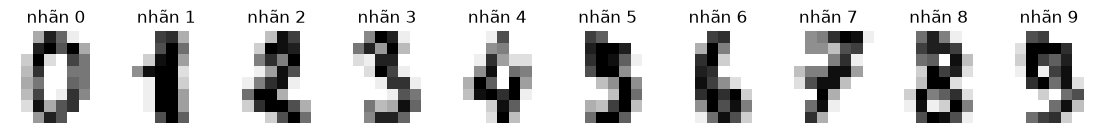

In [18]:
# 5.1 — Tải digits, hiển thị 10 ảnh đầu
digits = load_digits()
X_dg, y_dg = digits.data, digits.target
print(X_dg.shape, "| pixel trong khoảng", X_dg.min(), "→", X_dg.max())

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for ax, img, label in zip(axes, digits.images[:10], y_dg[:10]):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(f"nhãn {label}"); ax.axis("off")
plt.show()

In [19]:
# 5.2 — Chia 80/20 có stratify, đưa pixel về [0, 1]
Xtr_dg, Xte_dg, ytr_dg, yte_dg = train_test_split(
    X_dg / 16.0, y_dg, test_size=0.2, stratify=y_dg, random_state=42)
print(Xtr_dg.shape, Xte_dg.shape)
print("số mẫu mỗi lớp (test):", np.bincount(yte_dg))

(1437, 64) (360, 64)
số mẫu mỗi lớp (test): [36 36 35 37 36 37 36 36 35 36]


In [20]:
# 5.3 — one_hot và class SoftmaxRegressionGD
def one_hot(y, K):
    Y = np.zeros((len(y), K))
    Y[np.arange(len(y)), y] = 1.0
    return Y

def cross_entropy_from_logits(Z, Y):
    """Trung bình −Σ_k Y_k·log softmax(Z)_k, tính bằng log-sum-exp ổn định."""
    m = Z.max(axis=1, keepdims=True)
    log_sum_exp = m.ravel() + np.log(np.exp(Z - m).sum(axis=1))
    return np.mean(log_sum_exp - np.sum(Z * Y, axis=1))

class SoftmaxRegressionGD:
    def __init__(self, lr=0.1, batch_size=32, momentum=0.0, seed=0):
        self.lr, self.batch_size, self.momentum = lr, batch_size, momentum
        self.rng_ = np.random.default_rng(seed)
        self.W_ = None
        self.loss_history_ = []

    # W có shape (d+1, K), X đã có cột bias, Y one-hot (n, K)
    @staticmethod
    def loss(W, X, Y):
        return cross_entropy_from_logits(X @ W, Y)

    @staticmethod
    def grad(W, X, Y):
        return X.T @ (softmax(X @ W) - Y) / len(X)

    def fit(self, X, y, epochs=1):
        """Gọi nhiều lần sẽ train tiếp từ W hiện tại (warm start)."""
        Xb = add_bias(X)
        if self.W_ is None:
            self.K_ = int(y.max()) + 1
            self.W_ = np.zeros((Xb.shape[1], self.K_))
        self.W_, losses = train_gd(
            Xb, one_hot(y, self.K_), self.loss, self.grad, self.W_,
            lr=self.lr, batch_size=self.batch_size, epochs=epochs,
            momentum=self.momentum, seed=self.rng_)
        self.loss_history_ += losses
        return self

    def predict_proba(self, X):
        return softmax(add_bias(X) @ self.W_)

    def predict(self, X):
        return np.argmax(add_bias(X) @ self.W_, axis=1)

In [21]:
# 5.4 — Kiểm tra gradient trên 20 mẫu
rng = np.random.default_rng(0)
idx = rng.choice(len(Xtr_dg), size=20, replace=False)
X20, Y20 = add_bias(Xtr_dg[idx]), one_hot(ytr_dg[idx], 10)
W_rand = rng.normal(scale=0.1, size=(X20.shape[1], 10))

G_ana = SoftmaxRegressionGD.grad(W_rand, X20, Y20)
G_num = numerical_grad(lambda W: SoftmaxRegressionGD.loss(W, X20, Y20), W_rand)
err = rel_error(G_ana, G_num)
print("shape gradient:", G_ana.shape)
print(f"sai khác tương đối = {err:.2e}")
assert err < 1e-7, "Gradient sai!"

shape gradient: (65, 10)
sai khác tương đối = 1.86e-10


In [22]:
# 5.5 — Train từng epoch đến khi accuracy test > 90%
sm_clf = SoftmaxRegressionGD(lr=0.1, batch_size=32, seed=0)
test_acc = []
for epoch in range(1, 201):
    sm_clf.fit(Xtr_dg, ytr_dg, epochs=1)
    test_acc.append(np.mean(sm_clf.predict(Xte_dg) == yte_dg))
    print(f"epoch {epoch:3d}: loss train = {sm_clf.loss_history_[-1]:.4f}, accuracy test = {test_acc[-1]:.4f}")
    if test_acc[-1] > 0.90:
        break

epoch   1: loss train = 1.6029, accuracy test = 0.8500
epoch   2: loss train = 1.1882, accuracy test = 0.8639
epoch   3: loss train = 0.9436, accuracy test = 0.8861
epoch   4: loss train = 0.7861, accuracy test = 0.8917
epoch   5: loss train = 0.6791, accuracy test = 0.9028


hàng = nhãn thật, cột = dự đoán
        0   1   2   3   4   5   6   7   8   9
   0   35   0   0   0   1   0   0   0   0   0
   1    0  26   2   0   0   2   2   0   0   4
   2    1   1  33   0   0   0   0   0   0   0
   3    0   0   1  36   0   0   0   0   0   0
   4    0   2   0   0  33   0   0   1   0   0
   5    0   0   0   0   0  35   0   0   0   2
   6    0   1   0   0   0   0  34   0   1   0
   7    0   0   0   0   0   0   0  36   0   0
   8    0   7   1   0   0   0   0   2  25   0
   9    0   0   0   0   2   0   0   1   1  32

Cặp hay nhầm nhất: 1 ↔ 8  (0 lần 1→8, 7 lần 8→1)


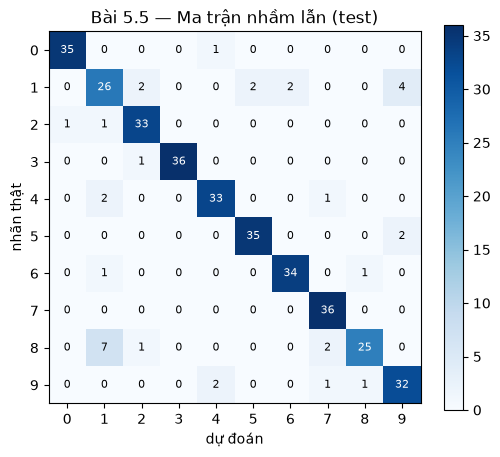

In [23]:
# 5.5b — Ma trận nhầm lẫn 10×10 tự viết: C[i, j] = số ảnh nhãn thật i bị đoán là j
def confusion_matrix_np(y_true, y_pred, K):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (y_true, y_pred), 1)
    return C

pred_dg = sm_clf.predict(Xte_dg)
C = confusion_matrix_np(yte_dg, pred_dg, 10)
print("hàng = nhãn thật, cột = dự đoán")
print("     " + "".join(f"{j:4d}" for j in range(10)))
for i in range(10):
    print(f"{i:4d} " + "".join(f"{C[i, j]:4d}" for j in range(10)))

# cặp hay nhầm nhất: cộng cả hai chiều i→j và j→i, bỏ đường chéo
pair = C + C.T
np.fill_diagonal(pair, 0)
i, j = np.unravel_index(np.argmax(np.triu(pair)), pair.shape)
print(f"\nCặp hay nhầm nhất: {i} ↔ {j}  ({C[i, j]} lần {i}→{j}, {C[j, i]} lần {j}→{i})")

plt.figure(figsize=(6, 5))
plt.imshow(C, cmap="Blues")
for a in range(10):
    for b in range(10):
        plt.text(b, a, C[a, b], ha="center", va="center",
                 color="white" if C[a, b] > C.max() / 2 else "black", fontsize=8)
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("dự đoán"); plt.ylabel("nhãn thật"); plt.title("Bài 5.5 — Ma trận nhầm lẫn (test)")
plt.colorbar(); plt.show()

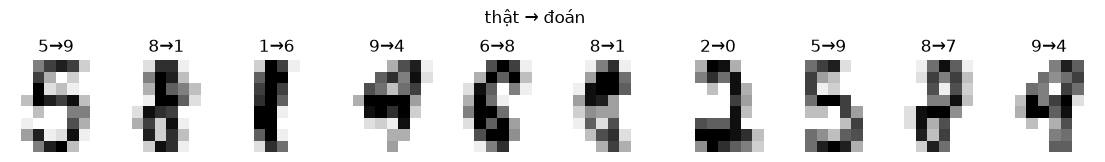

In [24]:
# 5.5c — Một vài ảnh bị đoán sai
wrong = np.where(pred_dg != yte_dg)[0][:10]
fig, axes = plt.subplots(1, len(wrong), figsize=(1.4 * len(wrong), 2))
for ax, k in zip(np.atleast_1d(axes), wrong):
    ax.imshow(Xte_dg[k].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"{yte_dg[k]}→{pred_dg[k]}"); ax.axis("off")
plt.suptitle("thật → đoán"); plt.show()

**Nhận xét 5.5:** Mô hình vượt 90% sau vài epoch. Trong ma trận nhầm lẫn, phần lớn lỗi tập trung ở vài cặp chữ số có nét giống nhau ở độ phân giải 8×8, nổi bật nhất là **8 ↔ 1**: 7 ảnh chữ 8 bị đoán là 1. Tiếp theo là 1 → 9 (4 lần). Chữ 8 viết mảnh hoặc nghiêng trông giống một nét dọc. Softmax regression chỉ là mô hình tuyến tính trên từng pixel, nên nó không nhận ra được "hai vòng tròn chồng nhau" mà chỉ so mức độ trùng pixel với một khuôn mẫu.

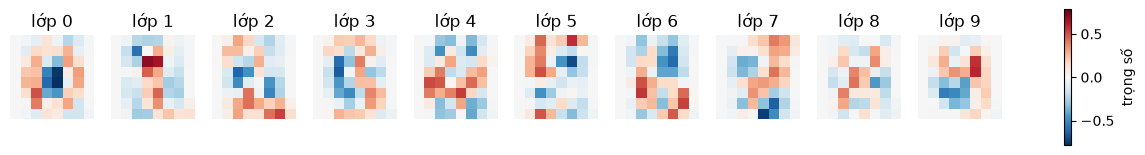

pixel luôn bằng 0 trong train: [ 0 32 39]
trọng số tại các pixel đó: 0.0


In [25]:
# 5.6 — 10 cột của W (bỏ hàng bias) dưới dạng ảnh 8×8
W_img = sm_clf.W_[1:]                       # (64, 10)
vmax = np.abs(W_img).max()
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for k, ax in enumerate(axes):
    im = ax.imshow(W_img[:, k].reshape(8, 8), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(f"lớp {k}"); ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="trọng số")
plt.show()

print("pixel luôn bằng 0 trong train:", np.where(Xtr_dg.max(axis=0) == 0)[0])
print("trọng số tại các pixel đó:", np.abs(W_img[Xtr_dg.max(axis=0) == 0]).max())

**Nhận xét 5.6:**
- Mỗi cột của W là một **khuôn mẫu (template)** cho một chữ số. Điểm của lớp k là tích vô hướng giữa ảnh và cột k. Vùng **đỏ** (trọng số dương) là nơi có nét mực thì ủng hộ lớp k, vùng **xanh** (âm) là nơi có mực thì phản đối lớp k. Có thể lờ mờ nhận ra hình chữ số: lớp 0 có vòng đỏ bao quanh một lỗ xanh ở giữa, còn lớp 1 có vệt đỏ dọc ở giữa.
- Trọng số học theo kiểu **phân biệt**, không chỉ "trung bình ảnh". Vùng xanh thường là chỗ mà các chữ số dễ nhầm có mực nhưng lớp k thì không, ví dụ chính giữa của chữ 0.
- Ba pixel (góc trên trái, và hai pixel ở mép trái/mép phải của hàng giữa) luôn bằng 0 trong train, nên gradient tại đó luôn bằng 0 và trọng số giữ nguyên giá trị khởi tạo 0. Các pixel khác ở viền cũng gần như luôn bằng 0, nên trọng số ở đó rất nhỏ (màu nhạt).
- Ảnh khá nhiễu vì mô hình tuyến tính và dừng sớm. Đây cũng là giới hạn của mô hình tuyến tính: mỗi lớp chỉ có **một** khuôn mẫu, không biểu diễn được nhiều cách viết khác nhau của cùng một chữ số.

## Tự kiểm tra

**1. Đạo hàm σ'(z) và gradient của binary cross-entropy.**

σ(z) = 1/(1 + e^{−z}) = (1 + e^{−z})^{−1}. Lấy đạo hàm:

$$\sigma'(z) = \frac{e^{-z}}{(1+e^{-z})^2} = \frac{1}{1+e^{-z}}\cdot\frac{e^{-z}}{1+e^{-z}} = \sigma(z)\,\bigl(1-\sigma(z)\bigr),$$

vì $\frac{e^{-z}}{1+e^{-z}} = 1 - \frac{1}{1+e^{-z}} = 1-\sigma(z)$.

BCE cho một mẫu với p = σ(z), z = wᵀx: ℓ = −[y log p + (1−y) log(1−p)].

$$\frac{\partial \ell}{\partial z} = -\Bigl[\frac{y}{p} - \frac{1-y}{1-p}\Bigr]\,p(1-p) = -\bigl[y(1-p) - (1-y)p\bigr] = p - y.$$

Vì ∂z/∂w = x, ta có ∂ℓ/∂w = (p − y)·x. Lấy trung bình trên n mẫu:

$$\nabla_w L = \frac{1}{n} X^\top(\sigma(Xw) - y).$$

Công thức này có cùng dạng với linear regression, chỉ thay Xw bằng σ(Xw). Hạng σ' bị triệt tiêu gọn gàng.

**2. Vì sao cross-entropy tốt hơn MSE cho phân lớp?**
- **Gradient không tắt:** với MSE trên σ(z), ∂L/∂z = (p − y)·p(1 − p). Khi mô hình sai mà rất tự tin (p ≈ 0, y = 1) thì p(1 − p) ≈ 0, gradient gần như bằng 0 và học rất chậm. Với CE, ∂L/∂z = p − y ≈ −1, sai càng nhiều thì gradient càng lớn.
- **Lồi:** CE theo w là hàm lồi, nên chỉ có một cực tiểu. MSE kết hợp sigmoid thì không lồi, có vùng phẳng và có thể có cực tiểu địa phương.
- **Ý nghĩa xác suất:** CE chính là negative log-likelihood của mô hình Bernoulli/Categorical, tức tối ưu CE là ước lượng hợp lý cực đại (MLE). CE phạt rất nặng các dự đoán sai mà tự tin (→ ∞), còn MSE chỉ phạt tối đa 1.

**3. Logistic regression có vẽ được biên quyết định hình tròn không?**
Trên đặc trưng gốc (x₁, x₂) thì **không**: biên là wᵀx = 0, luôn là đường thẳng (siêu phẳng). Nhưng mô hình tuyến tính theo *đặc trưng*, nên có thể thêm đặc trưng phi tuyến như ở Bài 5 ngày 3. Ví dụ dùng [x₁, x₂, x₁², x₂²] (hoặc PolynomialFeatures bậc 2), biên w₀ + w₁x₁ + w₂x₂ + w₃x₁² + w₄x₂² = 0 có thể là đường tròn hoặc ellipse. Cách khác là dùng kernel, hoặc mạng neural để tự học đặc trưng.

**4. Vì sao trừ max(z) không đổi kết quả softmax?**
Với mọi hằng số c:

$$\frac{e^{z_k - c}}{\sum_j e^{z_j - c}} = \frac{e^{-c}\,e^{z_k}}{e^{-c}\sum_j e^{z_j}} = \frac{e^{z_k}}{\sum_j e^{z_j}}.$$

Thừa số e^{−c} triệt tiêu ở tử và mẫu. Chọn c = max(z) thì mọi số mũ ≤ 0, nên exp không tràn số (tối đa là e⁰ = 1), và mẫu số ≥ 1 nên không chia cho 0.

**5. LLM có từ vựng 100.000 token: lớp cuối và hàm loss liên hệ gì với bài hôm nay?**
Lớp cuối của LLM chính là **softmax regression** với K = 100.000 lớp. Vector ẩn h ∈ ℝᵈ của vị trí hiện tại đóng vai trò đặc trưng x, ma trận "unembedding" W ∈ ℝ^{d×100000} cho logit z = Wᵀh, rồi softmax(z) là phân phối xác suất của token tiếp theo. Loss huấn luyện là **cross-entropy** giữa phân phối đó và token thật (one-hot), lấy trung bình trên mọi vị trí. Đây đúng là `cross_entropy_from_logits` ở Bài 5, và gradient theo logit vẫn là softmax(z) − one_hot(y). Khác biệt chỉ là x không phải pixel cố định mà do transformer học ra. Vì K rất lớn, việc tính log-sum-exp ổn định (trừ max) càng quan trọng. Perplexity mà người ta hay báo cáo chính là exp(cross-entropy).

**6. Vì sao PyTorch khuyên truyền logit thay vì xác suất vào hàm loss?**
- **Ổn định số:** `BCEWithLogitsLoss` và `CrossEntropyLoss` gộp sigmoid/softmax với log thành công thức log-sum-exp (như `logaddexp` ở Bài 1.2). Nếu tính sigmoid trước, xác suất bị làm tròn thành đúng 0 hoặc 1, log(0) = −∞, và phải kẹp ε. Kết quả là loss bị chặn (≈ 34.5 ở Bài 1.2) và gradient sai hoặc bằng 0 đúng lúc mô hình sai nặng nhất.
- **Gradient chính xác và gọn:** đạo hàm theo logit là p − y, tính trực tiếp không qua phép chia cho p(1 − p) có thể rất nhỏ.
- **Hiệu quả:** một phép tính gộp thay vì hai, ít bộ nhớ trung gian hơn. Vì vậy mô hình PyTorch thường để lớp cuối xuất logit thô, chỉ gọi sigmoid/softmax khi cần xác suất lúc suy luận.